# Extra experiments to check the performance of Lagrangian Kriging with increasing observations and prediction points. 

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from src.matrices import CovM, Umat, CovFn

Importing covderivatives.py


In [ ]:
# Constants
PI = np.pi
seed = 20                                               # Reproducibility 
np.random.seed(seed)

## Unknown function and ODE: f+f'' = 0
f = lambda X: np.sin(X)
fx = lambda X: np.cos(X)
fxx = lambda X: -np.sin(X)

# Inputs
disc: int = 100                                         # Discretization of the input space
xl: float = 0.0                                         # Lower limit
xr: float = 2 * PI                                      # in radians
limits = (xl, xr)  
X = np.linspace(*limits, disc)                          # input array
nfobs: int = 4                                          # Observations of the actual function
nfpred: int = 1000                                      # prediction points, [= disc] for whole domain    
sigma: float = 1.0                                      # Noise variance parameter
theta: float = 1.12                                     # Correlation parameter
IMGPATH = r'IMAGES/'                                    # Image path
figsave = 1                                             # 1 => save images. 

In [3]:
# defining functions
###########################
## Simple Lagrangian Kriging: final prediction
###########################
def LagKrig(Kinv, H, v, ytrue, U, **kwargs):
    '''
    LagKrig
    
    :param Kinv: K inverse
    :param H: H matrix
    :param v: RHS of constraints
    :param ytrue: True observations
    :param U: U matrix
    :param kwargs: Pass UTUinv

    Feel free to pass UTUinv as a keyword argument.
    '''
    if 'UTUinv' in kwargs:
        # print('Using U^T U inverse given')
        UTUinv = kwargs.get('UTUinv')
    else:
        # print('Computing U^T U inverse')
        UTU = U.T @ U
        I = np.eye(UTU.shape[0])
        UTUinv =  np.linalg.solve(UTU, I)
    HKZ = H.T @ Kinv @ ytrue                            # Simple Kriging prediction
    prediction = (U @ UTUinv @ (v - U.T @ HKZ)) + HKZ
    return prediction

################################################
## Simple Lagrangian Kriging: Uncertainty Quantification
################################################
def LagVar(Zpred, Kinv, H, v, ytrue, U, **kwargs):
    '''
    MMSE prediction (Conditional variance approximation)
    
    :param Zpred: Prediction locations and resp. orders of derivatives.
    :param Kinv: K inverse
    :param H: Matrix H
    :param v: RHS of constraints
    :param ytrue: Observed y values
    :param U: Coefficient matrix
    :param kwargs: Extra

    Feel free to pass `UTUinv`, `lamda`, `gamma`, `thetaopt` and `sigmaopt` as a keyword arguments. 
    '''
    theta = 1.0; sigma = 1.0                            # Default. Pass the optimal kernel params as keyword arguments
    if 'UTUinv' in kwargs:
        # print('Using U^T U inverse given')
        UTUinv = kwargs.get('UTUinv')
    else:
        # print('Computing U^T U inverse')
        UTU = U.T @ U
        I = np.eye(UTU.shape[0])
        UTUinv =  np.linalg.solve(UTU, I)               # (U^T U)^{-1} 
    if 'gamma' in kwargs:
        # print('Using gamma value given')
        gamma = kwargs.get('gamma')
    else:
        # print('Computing gamma value')
        gamma = ytrue.T @ Kinv @ ytrue                  # Z^T K^{-1} Z, RKHS norm
    HKZ = H.T @ Kinv @ ytrue                            # H^T K^{-1} Z, Simple Kriging prediction
    if 'lamda' in kwargs:
        # print('Using lambda (Lagrange multipliers) values given')
        lamda = kwargs.get('lamda')
    else:
        # print('Computing lambda values')
        lamda = (1/gamma) * UTUinv @ (v - (U.T @ HKZ))  # Lagrange multipliers
    
    ## Please pass optimal kernel parameters
    if 'thetaopt' in kwargs:
        theta = kwargs.get('thetaopt')
    if 'sigmaopt' in kwargs:
        sigma = kwargs.get('sigmaopt')

    ## final variance equation
    # Kstar = CovM(Zpred, thetaval = theta,               # Unconditional covariance.
    #                     sigmaval = sigma) 
    # # print(f'{np.diag(Kstar)=}')

    # # Only the unconditional variance (diagonal of the covariance matrix)
    CovParam = lambda *Zvals: CovFn(*Zvals, thetaval = theta,   # Optimal coefficients
                                            sigmaval = sigma).item() 
    Kstar = np.array(list(map(CovParam, Zpred, Zpred)))

    M1 = np.outer(ytrue, lamda) @ U.T
    M2 = (H + M1).T @ Kinv @ (M1 - H)                   # LK contribution
    # Var = np.diag(Kstar + M2)                           # IF whole unconditional covariance
    Var = Kstar + np.diag(M2)                           # IF only unconditional variance
    # print(f'{Var =}')
    BaseVar = 0.0                                       # To make sure Conditional variance estimate is positive. 
    return np.sqrt(Var + BaseVar)  

In [13]:
# Creating important arrays
xfobs = np.array([0., 2.35330497,                       # Original code observations
                  4.59925358, 5.97351416])  
# xfobs = np.zeros(nfobs)
# xfobs[1:] = np.random.uniform(*limits, nfobs - 1)  
xfobs.sort(); xfpred = np.linspace(*limits, nfpred)     # Prediction locations of f
Zobs = np.zeros((xfobs.shape[0], 2))                    # Extended design space: Z = (fval, m)
Zpred = np.zeros((xfpred.shape[0], 2))                  # To predict: f
Zxxpred = 2 * np.ones((xfpred.shape[0], 2))             # To satisfy constraints involving: f''
Zobs[:, 0] = xfobs                                      # Observation locations of f
Zpred[:, 0] = xfpred; Zxxpred[:, 0] = xfpred            # f, f'' at prediction locations 
ExtZpred = np.zeros((2 * nfpred, 2))                    # CAUTION: This might need changing. The factor of two appears because binary operation (f + f'')
for _, i in zip(range(nfpred), range(0, 2 * nfpred, 2)):
    ExtZpred[i, :] = Zpred[_, :]
    ExtZpred[i + 1, :] = Zxxpred[_, :]

In [14]:
# kernel parameters
theta = 1.12; sigma = 0.61                              # LOOCV optimal hyperparams
kernelkwargs = dict(thetaval = theta, sigmaval = sigma)

# Matrix K
n = xfobs.shape[0]
K = CovM(Zobs, **kernelkwargs)
I = np.eye(n); nI = 1e-10 * I                           # nugget effect: nugget = 1e-10 to ensure PSD matrix
Kinv = np.linalg.solve(K + nI, I)                       # K matrix inverse

# Matrix U
q = xfpred.shape[0]                                     # of prediction locations
U = Umat([1,1], q)                                      # Coefficients 1 * f + 1 * f'' at q prediction locations

# vector v
v = np.zeros(q)                                         # RHS of constraint equations

# Matrix H
H = CovM(Zobs, ExtZpred, **kernelkwargs)                # Extended prediction covariance

##############################
# Lagrangian Kriging Predictions
##############################
ytrue = f(xfobs)
AllPred = LagKrig(Kinv, H, v, ytrue, U)                 # all predcitions of f and f''.
AllSigma = LagVar(ExtZpred, Kinv, H, v, ytrue, U,       # all standard devs of f and f''.
                  thetaopt = theta, 
                  sigmaopt = sigma)
yhat = AllPred[::2]                                     # The predictions are arranged in a criss-cross fashion
ysig = AllSigma[::2]                                    # The predictions are arranges in a criss-cross fashion.



## n = 4, q = 1000 (LOOCV optimal)

<>:19: SyntaxWarning: invalid escape sequence '\p'
<>:19: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_1986175/168456890.py:19: SyntaxWarning: invalid escape sequence '\p'
  plt.fill_between(xfpred, low, high, label = '$\pm 2\sigma$ CI', **fkwargs)  # Confidence intervals


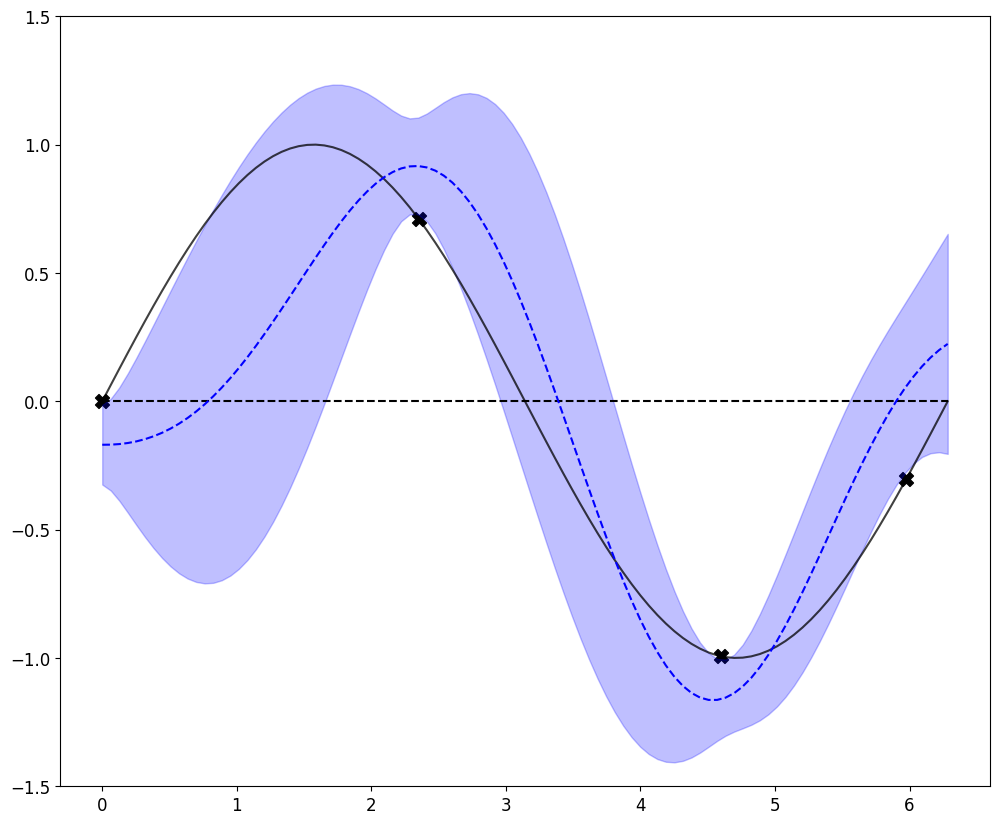

In [15]:
###############################
# visualizing the predictions. 
###############################
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})                                                     
plt.figure(figsize = (12,10))
lkwargs = dict(ls = '-', lw = 1.5, alpha = 0.75, c = 'k')                           
plt.plot(X, f(X), label = 'f(x) = sin (x)', **lkwargs);                     # True function
# skwargs = dict(c = 'green', marker = 'o', s = 75)
# plt.scatter(xfpred, nfpred * [0], label = 'Prediction locations', **skwargs);  # f + f'' = 0
skwargs = dict(c = 'k', marker = 'X', s = 100)
plt.scatter(xfobs, f(xfobs), label = 'True observations', **skwargs);       # sparse TRUE observations (f)
plt.plot(X, X.shape[0]*[0], 'k--')                                          # An x-axis
## f prediction
lkwargs = dict(ls = '--', lw = 1.5, c = 'blue')                 
plt.plot(xfpred, yhat, label = 'Predicted f', **lkwargs)                    # Predictions
## UQ
cI = 2; low = yhat - (cI * ysig); high = yhat + (cI * ysig)                 # Confidence interval factor
fkwargs = dict(color = 'b', alpha = 0.25);
plt.fill_between(xfpred, low, high, label = '$\pm 2\sigma$ CI', **fkwargs)  # Confidence intervals
plt.ylim(-1.5, 1.5)                                                         # ylim optional
if figsave == 1:
    plt.savefig(IMGPATH+'LK1Dq1000-LOOCV.pdf', dpi = 300, pad_inches = 0, bbox_inches = 'tight')


## n = 4, q = 1000 (Interpolation error optimal)

<>:50: SyntaxWarning: invalid escape sequence '\p'
<>:50: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_1986175/1394533587.py:50: SyntaxWarning: invalid escape sequence '\p'
  plt.fill_between(xfpred, low, high, label = '$\pm 2\sigma$ CI', **fkwargs) # Confidence intervals


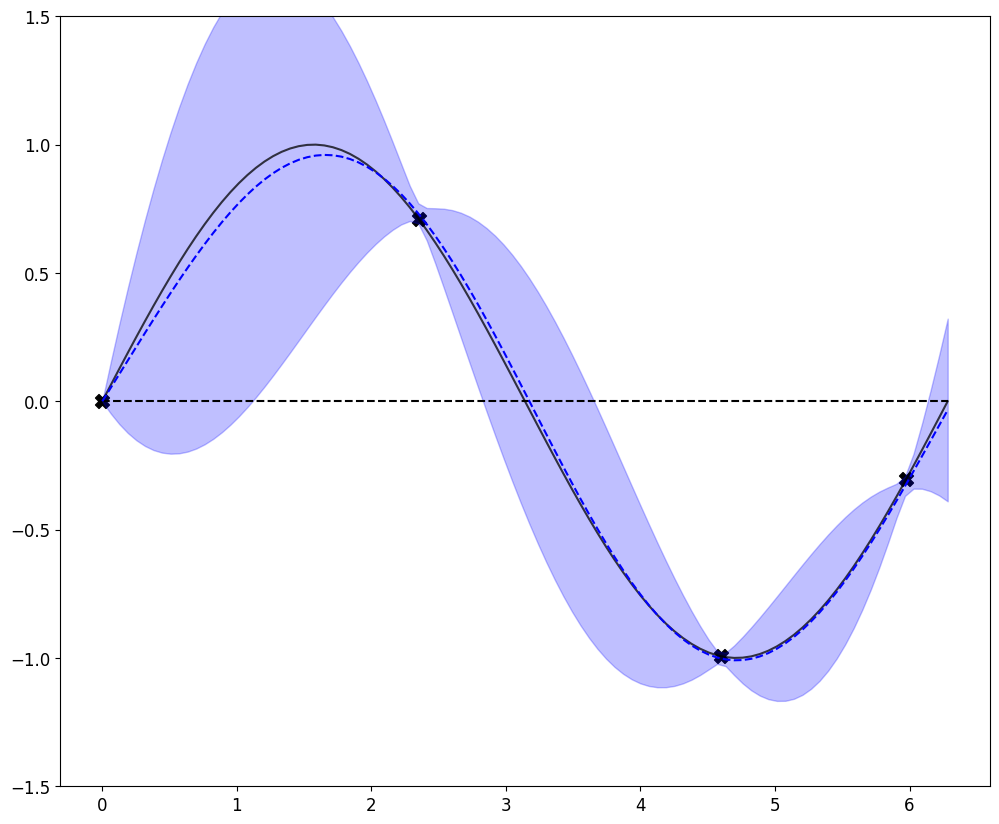

In [16]:
# kernel parameters
theta = 2.38; sigma = 3.91                              # LOOCV optimal hyperparams
kernelkwargs = dict(thetaval = theta, sigmaval = sigma)

# Matrix K
n = xfobs.shape[0]
K = CovM(Zobs, **kernelkwargs)
I = np.eye(n); nI = 1e-10 * I                           # nugget effect: nugget = 1e-10 to ensure PSD matrix
Kinv = np.linalg.solve(K + nI, I)                       # K matrix inverse

# Matrix U
q = xfpred.shape[0]                                     # of prediction locations
U = Umat([1,1], q)                                      # Coefficients 1 * f + 1 * f'' at q prediction locations

# vector v
v = np.zeros(q)                                         # RHS of constraint equations

# Matrix H
H = CovM(Zobs, ExtZpred, **kernelkwargs)                # Extended prediction covariance

##############################
# Lagrangian Kriging Predictions
##############################
ytrue = f(xfobs)
AllPred = LagKrig(Kinv, H, v, ytrue, U)                 # all predcitions of f and f''.
AllSigma = LagVar(ExtZpred, Kinv, H, v, ytrue, U,       # all standard devs of f and f''.
                  thetaopt = theta, 
                  sigmaopt = sigma)
yhat = AllPred[::2]                                     # The predictions are arranged in a criss-cross fashion
ysig = AllSigma[::2]                                    # The predictions are arranges in a criss-cross fashion.

###############################
# visualizing the predictions. 
###############################
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})                                                     
plt.figure(figsize = (12,10))
lkwargs = dict(ls = '-', lw = 1.5, alpha = 0.75, c = 'k')                           
plt.plot(X, f(X), label = 'f(x) = sin (x)', **lkwargs);                     # True function
# skwargs = dict(c = 'green', marker = 'o', s = 75)
# plt.scatter(xfpred, nfpred * [0], label = 'Prediction locations', **skwargs);  # f + f'' = 0
skwargs = dict(c = 'k', marker = 'X', s = 100)
plt.scatter(xfobs, f(xfobs), label = 'True observations', **skwargs);       # sparse TRUE observations (f)
plt.plot(X, X.shape[0]*[0], 'k--')                                          # An x-axis
## f prediction
lkwargs = dict(ls = '--', lw = 1.5, c = 'blue')                 
plt.plot(xfpred, yhat, label = 'Predicted f', **lkwargs)                      # Predictions
## UQ
cI = 2; low = yhat - (cI * ysig); high = yhat + (cI * ysig)                 # Confidence interval factor
fkwargs = dict(color = 'b', alpha = 0.25);
plt.fill_between(xfpred, low, high, label = '$\pm 2\sigma$ CI', **fkwargs) # Confidence intervals
plt.ylim(-1.5, 1.5)                                                         # ylim optional
if figsave == 1:
    plt.savefig(IMGPATH+'LK1Dq1000-InterpolationError.pdf', dpi = 300, pad_inches = 0, bbox_inches = 'tight')

# Effect of increasing observations


In [8]:

# kernel parameters
theta = 1.0; sigma = 1.0                                    # Fixed kernel params (theta = 1)
kernelkwargs = dict(thetaval = theta, sigmaval = sigma)

# Creating important arrays
def CreateArrays(nfobs, nfpred=100):
    xfobs = np.zeros(nfobs)
    xfobs[1:] = np.random.uniform(*limits, nfobs - 1)  
    xfobs.sort();      
    Zobs = np.zeros((xfobs.shape[0], 2))                    # Extended design space: Z = (fval, m)
    Zobs[:, 0] = xfobs                                      # Observation locations of f
    return Zobs, xfobs, f(xfobs)

def visualize(yhat, namestring: str):
    ###############################
    # visualizing the predictions. 
    ###############################
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})                                                     
    plt.figure(figsize = (12,10))
    lkwargs = dict(ls = '-', lw = 1.5, alpha = 0.75, c = 'k')                           
    plt.plot(X, f(X), label = 'f(x) = sin (x)', **lkwargs);                     # True function
    # skwargs = dict(c = 'green', marker = 'o', s = 75)
    # plt.scatter(xfpred, nfpred * [0], label = 'Prediction locations', **skwargs);  # f + f'' = 0
    skwargs = dict(c = 'k', marker = 'X', s = 100)
    plt.scatter(xfobs, f(xfobs), label = 'True observations', **skwargs);       # sparse TRUE observations (f)
    plt.plot(X, X.shape[0]*[0], 'k--')                                          # An x-axis
    ## f prediction
    lkwargs = dict(ls = '--', lw = 1.5, c = 'blue')                 
    plt.plot(xfpred, yhat, label = 'Predicted f', **lkwargs)                      # Predictions
    if figsave == 1:
        plt.savefig(IMGPATH+namestring+'.pdf', dpi = 300, pad_inches = 0, bbox_inches  = 'tight')
    

## n=2, q = 100

In [9]:

nfpred = 100                                            # q
xfpred = np.linspace(*limits, nfpred)                   # prediction locations of f and f''
Zpred = np.zeros((xfpred.shape[0], 2))                  # To predict: f
Zxxpred = 2 * np.ones((xfpred.shape[0], 2))             # To satisfy constraints involving: f''
Zpred[:, 0] = xfpred; Zxxpred[:, 0] = xfpred            # f, f'' at prediction locations 
ExtZpred = np.zeros((2 * nfpred, 2))                    # CAUTION: This might need changing. The factor of two appears because binary operation (f + f'')
for _, i in zip(range(nfpred), range(0, 2 * nfpred, 2)):
    ExtZpred[i, :] = Zpred[_, :]
    ExtZpred[i + 1, :] = Zxxpred[_, :]

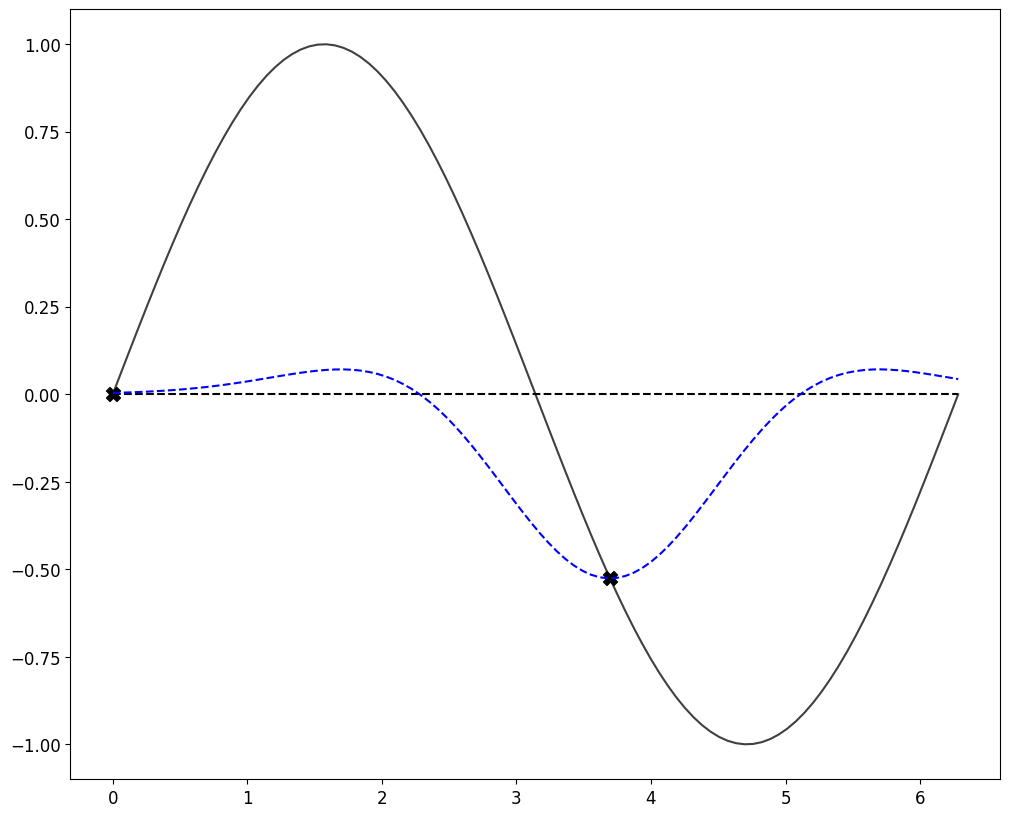

In [10]:
Zobs, xfobs, ytrue = CreateArrays(nfobs=2)              # Number of observations

# Matrix K
n = Zobs.shape[0]
K = CovM(Zobs, **kernelkwargs)
I = np.eye(n); nI = 1e-10 * I                           # nugget effect: nugget = 1e-10 to ensure PSD matrix
Kinv = np.linalg.solve(K + nI, I)                       # K matrix inverse

# Matrix U
q = nfpred                                              # of prediction locations
U = Umat([1,1], q)                                      # Coefficients 1 * f + 1 * f'' at q prediction locations

# vector v
v = np.zeros(q)                                         # RHS of constraint equations

# Matrix H
H = CovM(Zobs, ExtZpred, **kernelkwargs)                # Extended prediction covariance

##############################
# Lagrangian Kriging Predictions
##############################
AllPred = LagKrig(Kinv, H, v, ytrue, U)                 # all predcitions of f and f''.
yhat = AllPred[::2]                                     # The predictions are arranged in a criss-cross fashion

# visualization
visualize(yhat, 'LK1Dn2')

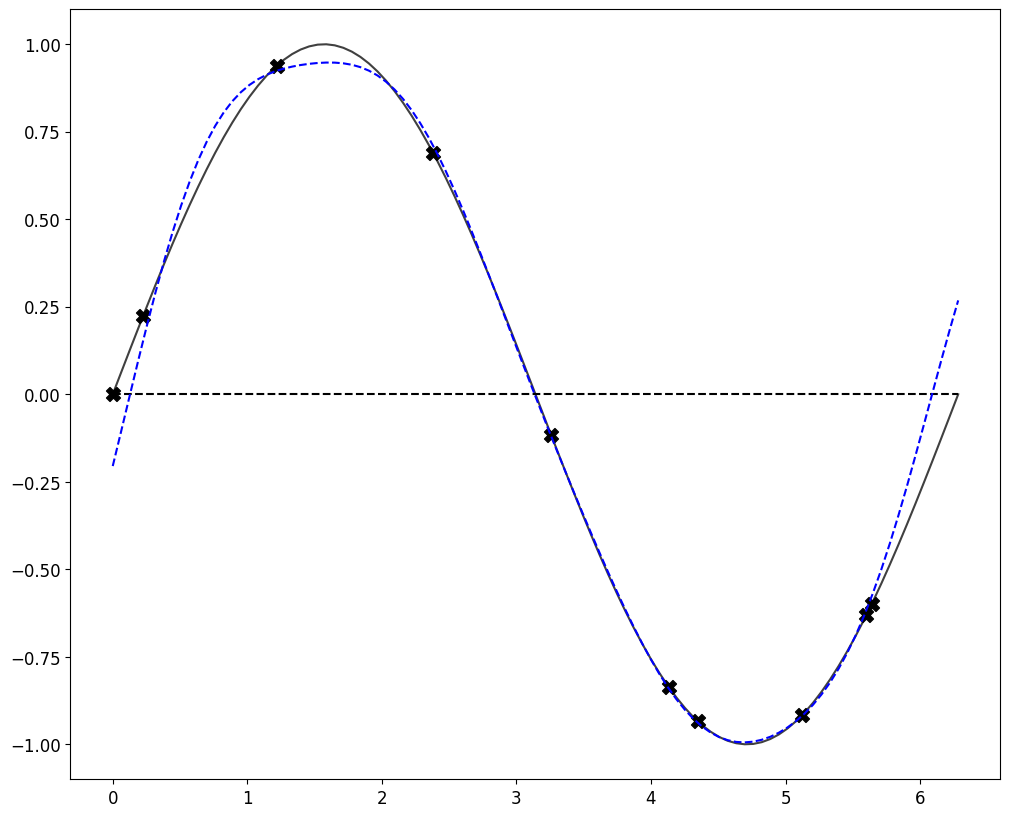

In [11]:
Zobs, xfobs, ytrue = CreateArrays(nfobs=10)             # Number of observations

# Matrix K
n = Zobs.shape[0]
K = CovM(Zobs, **kernelkwargs)
I = np.eye(n); nI = 1e-10 * I                           # nugget effect: nugget = 1e-10 to ensure PSD matrix
Kinv = np.linalg.solve(K + nI, I)                       # K matrix inverse

# Matrix U
q = nfpred                                              # of prediction locations
U = Umat([1,1], q)                                      # Coefficients 1 * f + 1 * f'' at q prediction locations

# vector v
v = np.zeros(q)                                         # RHS of constraint equations

# Matrix H
H = CovM(Zobs, ExtZpred, **kernelkwargs)                # Extended prediction covariance

##############################
# Lagrangian Kriging Predictions
##############################
AllPred = LagKrig(Kinv, H, v, ytrue, U)                 # all predcitions of f and f''.
yhat = AllPred[::2]                                     # The predictions are arranged in a criss-cross fashion

# visualization
visualize(yhat, 'LK1Dn10')

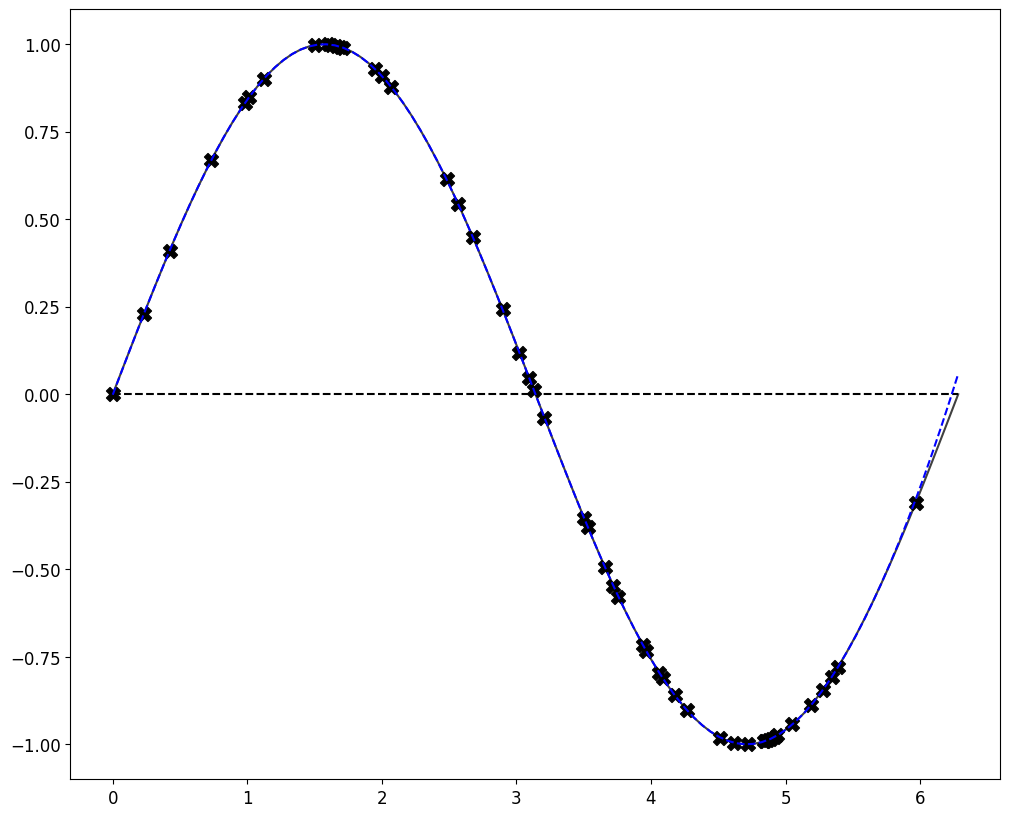

In [12]:
Zobs, xfobs, ytrue = CreateArrays(nfobs=50)             # Number of observations

# Matrix K
n = Zobs.shape[0]
K = CovM(Zobs, **kernelkwargs)
I = np.eye(n); nI = 1e-10 * I                           # nugget effect: nugget = 1e-10 to ensure PSD matrix
Kinv = np.linalg.solve(K + nI, I)                       # K matrix inverse

# Matrix U
q = nfpred                                              # of prediction locations
U = Umat([1,1], q)                                      # Coefficients 1 * f + 1 * f'' at q prediction locations

# vector v
v = np.zeros(q)                                         # RHS of constraint equations

# Matrix H
H = CovM(Zobs, ExtZpred, **kernelkwargs)                # Extended prediction covariance

##############################
# Lagrangian Kriging Predictions
##############################
AllPred = LagKrig(Kinv, H, v, ytrue, U)                 # all predcitions of f and f''.
yhat = AllPred[::2]                                     # The predictions are arranged in a criss-cross fashion

# visualization
visualize(yhat, 'LK1Dn50')